<!-- This is a template that you should use to generate your lab reports for AE801 course work-->
# **Lab Report: Title of the topic**

# Required packages

In [2]:
# do not change line below
from google.colab import files

# import required packages here
import numpy as np
import matplotlib.pyplot as plt

# Problem statement

# Approach and numerical method

# Numerical algorithm

In [3]:
'Circular Cylinder'
def circle(n):

  theta =np.linspace(2*np.pi,0,n+1)
  r = 1
  a = r*np.cos(theta)
  b = r*np.sin(theta)
  #a**2 +b**2 == 1
  return (a,b)





In [4]:
#generating 3 random numbers for the NACA airfoil

Max_camber = np.random.randint(1,6)
Max_c_location = np.random.randint(1.5,6)
Thickness = np.random.randint(6,15)

#print(Max_camber,Max_c_location,Thickness)

m = Max_camber/100
p = Max_c_location/10
t = Thickness/100

#print(m,p,t)

In [5]:
def Air_foil0(n,str):
  if str == 'symmetric':
    m = 0
    p = 0
    t = 0.12
  elif str == 'asymmetric':
    m = 2/100
    p = 4/10
    t = 0.12


  i = int(n/2)
  a = np.linspace(0, np.pi, i+1)
  x = 0.5*(1 - np.cos(a))
  #creating n points for the x axis
  #print(x)

  # Corresponding y values for the generated x values.
  y_t = 5*t*(0.2969*(x**0.5) - 0.1260*(x) - 0.3516*(x**2) + 0.2843*(x**3) - 0.1036*(x**4)) # y_t is thickness value

  # evaluating y values for the x to plot the camber line
  y_c = np.where(x <= p, (m/p**2) * (2*p*x - x**2), (m/(1-p)**2) * ((1 - 2*p) + 2*p*x - x**2))
  #print(y_c)

  # Evaluating x,y values for the upper and lower surfaces.
  # So that the increment in y value due to the camber is perpendicular to the surface and not just along the y-axis
  d_yc = np.where(x <= p, (2*m/p**2) * (p - x),(2*m/(1-p)**2) * (p - x) )

  Theta = np.arctan(d_yc)

  x_u = x - y_t*np.sin(Theta)
  y_u = y_c + y_t*np.cos(Theta)
  x_l = x + y_t*np.sin(Theta)
  y_l = y_c - y_t*np.cos(Theta)
  #print(x_u,x_l)

  x_low = np.flip(x_l)
  y_low = np.flip(y_l)
  #print(x_l)
  X = np.concatenate([x_low,x_u[1:]])
  Y = np.concatenate([y_low,y_u[1:]])
  #print(X[200],X[401])
  #print(X,Y)
  return X,Y

In [6]:
def Air_foil(n,str):
  if str == 'symmetric':
    m = 0
    p = 0
    t = 0.12
  elif str == 'asymmetric':
    m = 2/100
    p = 4/10
    t = 0.12

  i = int(n/2)
  a = np.linspace(0, np.pi, i+1)
  x = 0.5*(1 - np.cos(a))

  # Corresponding y values for the generated x values.
  y_t = 5*t*(0.2969*(x**0.5) - 0.1260*(x) - 0.3516*(x**2) + 0.2843*(x**3) - 0.1036*(x**4))

  # Handle symmetric and asymmetric cases for camber line and its derivative
  if m == 0 or p == 0:
    y_c = np.zeros_like(x)
    d_yc = np.zeros_like(x)
  else:
    # evaluating y values for the x to plot the camber line
    y_c = np.where(x <= p, (m/p**2) * (2*p*x - x**2), (m/(1-p)**2) * ((1 - 2*p) + 2*p*x - x**2))
    # Evaluating derivatives
    d_yc = np.where(x <= p, (2*m/p**2) * (p - x), (2*m/(1-p)**2) * (p - x))

  Theta = np.arctan(d_yc)

  x_u = x - y_t*np.sin(Theta)
  y_u = y_c + y_t*np.cos(Theta)
  x_l = x + y_t*np.sin(Theta)
  y_l = y_c - y_t*np.cos(Theta)

  x_low = np.flip(x_l)
  y_low = np.flip(y_l)

  X = np.concatenate([x_low, x_u[1:]])
  Y = np.concatenate([y_low, y_u[1:]])

  return X, Y

In [7]:
X_airfoil,Y_airfoil = Air_foil(20,'symmetric')
X_circle,Y_circle = circle(10)
print(X_airfoil,Y_airfoil)

[1.         0.97552826 0.9045085  0.79389263 0.6545085  0.5
 0.3454915  0.20610737 0.0954915  0.02447174 0.         0.02447174
 0.0954915  0.20610737 0.3454915  0.5        0.6545085  0.79389263
 0.9045085  0.97552826 1.        ] [ 1.66533454e-17 -3.50136226e-03 -1.30709457e-02 -2.64046500e-02
 -4.06861839e-02 -5.28615020e-02 -5.95567645e-02 -5.77118565e-02
 -4.60488284e-02 -2.58933127e-02  0.00000000e+00  2.58933127e-02
  4.60488284e-02  5.77118565e-02  5.95567645e-02  5.28615020e-02
  4.06861839e-02  2.64046500e-02  1.30709457e-02  3.50136226e-03
 -1.66533454e-17]


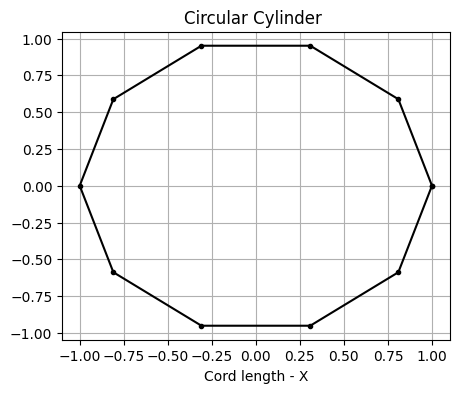

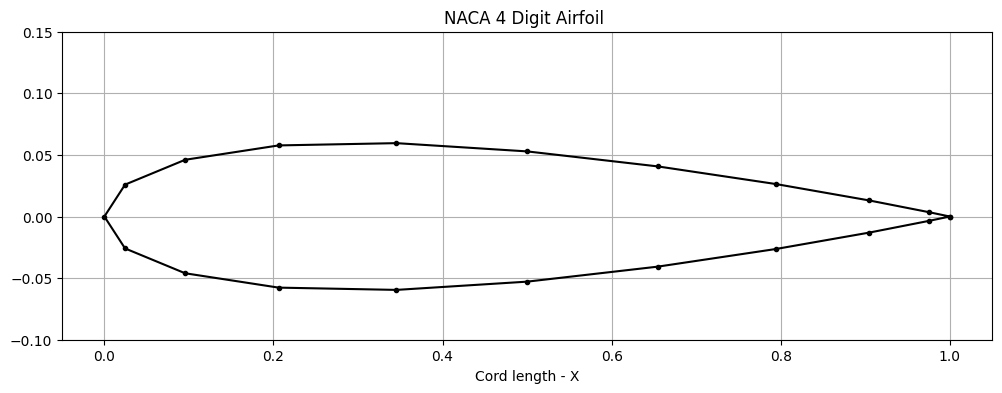

In [8]:
plt.figure(figsize=(5, 4))
plt.plot(X_circle,Y_circle,'o-',color='k',markersize = 3)
plt.title('Circular Cylinder ')
plt.xlabel('Cord length - X')
plt.grid()
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(X_airfoil,Y_airfoil,'o-',color='k',markersize = 3)
#mp.plot(x,y_c,'o-',markersize = 2)
plt.title('NACA 4 Digit Airfoil ')
plt.xlabel('Cord length - X')
plt.ylim(-0.1, 0.15)
plt.grid()
plt.show()



In [9]:
def panel_geometry(x_p,y_p):
  #x_p = np.array(x_p)
  #y_p = np.array(y_p)

  #x and y differeence
  dx = np.diff(x_p)
  dy = np.diff(y_p)
  #print(dx,dy)

  #center point
  x_c = (x_p[:-1] + x_p[1:])/2
  y_c = (y_p[:-1] + y_p[1:])/2
  #print(x_c,y_c)

  length = np.sqrt(dx**2 + dy**2)
  #print(length)

  theta = np.arctan(dy/dx)
  #print(theta)

  return x_c,y_c,length,theta


[0.98776413 0.94001838 0.84920056 0.72420056 0.57725425 0.42274575
 0.27579944 0.15079944 0.05998162 0.01223587 0.01223587 0.05998162
 0.15079944 0.27579944 0.42274575 0.57725425 0.72420056 0.84920056
 0.94001838 0.98776413] [-0.00175068 -0.00828615 -0.0197378  -0.03354542 -0.04677384 -0.05620913
 -0.05863431 -0.05188034 -0.03597107 -0.01294666  0.01294666  0.03597107
  0.05188034  0.05863431  0.05620913  0.04677384  0.03354542  0.0197378
  0.00828615  0.00175068]


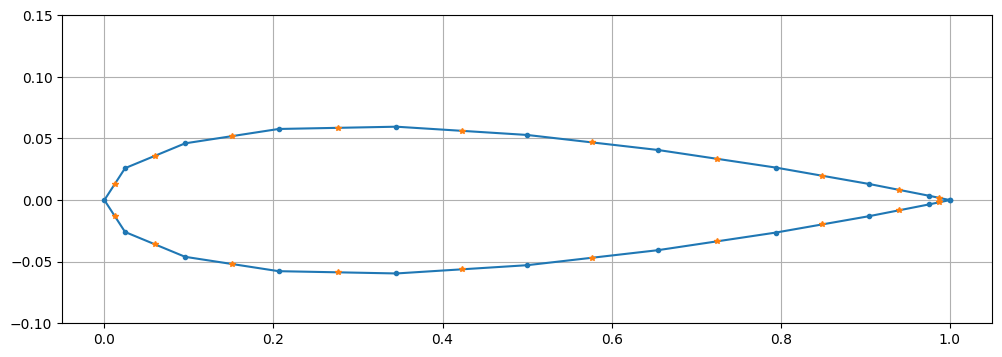

In [10]:
X,Y,S,theta = panel_geometry(X_airfoil,Y_airfoil)
print(X,Y)
plt.figure(figsize=(12, 4))
plt.plot(X_airfoil,Y_airfoil,'o-',markersize = 3)
plt.plot(X,Y,'*',markersize = 4)
plt.ylim(-0.1, 0.15)
plt.grid()
plt.show()

In [11]:
import math as math

def K_L_Matrix(XC,YC,XB,YB,phi,S):
    N_p = len(S)

    K = np.zeros([N_p,N_p])
    L = np.zeros([N_p,N_p])

    for i in range(N_p):
        for j in range(N_p):
            if (j != i):
                A  = -(XC[i]-XB[j])*np.cos(phi[j])-(YC[i]-YB[j])*np.sin(phi[j])
                B  = (XC[i]-XB[j])**2 + (YC[i]-YB[j])**2
                Cn = -np.cos(phi[i]-phi[j])
                Dn = (XC[i]-XB[j])*np.cos(phi[i])+(YC[i]-YB[j])*np.sin(phi[i])
                Ct = np.sin(phi[j]-phi[i])
                Dt = (XC[i]-XB[j])*np.sin(phi[i])-(YC[i]-YB[j])*np.cos(phi[i])
                E  = np.sqrt(B-A**2)
                if (E == 0 or np.iscomplex(E) or np.isnan(E) or np.isinf(E)):
                    K[i,j] = 0
                    L[i,j] = 0
                else:
                    term1  = 0.5*Cn*np.log((S[j]**2 + 2*A*S[j] + B)/B)
                    term2  = ((Dn-A*Cn)/E)*(math.atan2((S[j]+A),E)-math.atan2(A,E))
                    K[i,j] = term1 + term2

                    term1  = 0.5*Ct*np.log((S[j]**2 + 2*A*S[j] + B)/B)
                    term2  = ((Dt-A*Ct)/E)*(math.atan2((S[j]+A),E)-math.atan2(A,E))
                    L[i,j] = term1 + term2

            if (np.iscomplex(K[i,j]) or np.isnan(K[i,j]) or np.isinf(K[i,j])):
                K[i,j] = 0
            if (np.iscomplex(L[i,j]) or np.isnan(L[i,j]) or np.isinf(L[i,j])):
                L[i,j] = 0

    return K, L

In [12]:
def vortex_panel_method_0(xb, yb, alpha_deg, V_inf=1.0):
    alpha = np.deg2rad(alpha_deg)
    xc, yc, S, theta = panel_geometry(xb, yb)
    N = len(S)

    K, L = K_L_Matrix(xc, yc, xb, yb, theta, S)

    # Initialize A matrix and b vector
    A = np.zeros([N, N])
    b = np.zeros(N)

    # Populate A matrix and b vector for normal velocity boundary condition
    for i in range(N):
        for j in range(N):
            if i == j:
                A[i, j] = 0.0
            else:
                A[i, j] = -K[i, j]
        b[i] = -V_inf * 2 * np.pi * np.sin(alpha - theta[i])

    # Enforce the Kutta condition (gamma_1 + gamma_N = 0) at the trailing edge by replacing the last equation
    A[N-1, :] = 0.0
    A[N-1, 0] = 1.0
    A[N-1, N-1] = 1.0
    b[N-1] = 0.0

    # Solve for vortex densities (gamma)
    gamma = np.linalg.solve(A, b)

    # Compute local velocities along the panels using the L matrix (tangential components)
    V_t = np.zeros(N)
    for i in range(N):
        sum_tangential = 0.0
        for j in range(N):
            sum_tangential += L[i, j] * gamma[j]
        V_t[i] = V_inf * np.cos(alpha - theta[i]) + sum_tangential / (2 * np.pi)

    # Compute pressure coefficient (cp)
    cp = 1.0 - (V_t / V_inf)**2

    # Compute total circulation Gamma (sum of gamma * panel_length)
    Gamma = np.sum(gamma * S)

    # Compute chord length
    chord = np.max(xb) - np.min(xb)

    # Compute lift coefficient (cl)
    cl = 2.0 * Gamma / (V_inf * chord)

    return gamma, Gamma, cp, cl, chord, xc, yc

In [21]:
X_airfoil,Y_airfoil = Air_foil(100,'asymmetric')
gamma, Gamma, cp, cl, chord, xc, yc = vortex_panel_method_0(X_airfoil,Y_airfoil,0)
N = len(cp)
#print(gamma, Gamma, cp, cl, chord)


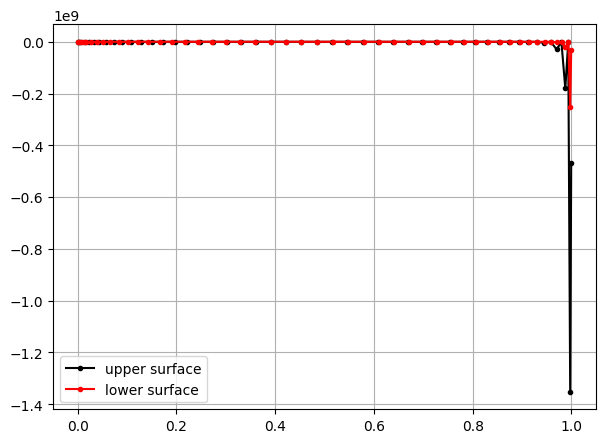

In [22]:
plt.figure(figsize=(7,5))
plt.plot(xc[:int(N*0.5)],cp[:int(N*0.5)],'o-',color = 'k',markersize = 3,label = 'upper surface')
plt.plot(xc[int(N*0.5+1):],cp[int(N*0.5+1):],'o-',color = 'r',markersize = 3,label = 'lower surface')
plt.legend()
plt.grid()
plt.show()

In [27]:

def vortex_panel_method_1(xb, yb, alpha_deg, V_inf=1.0):
    """
    A simplified linear-strength vortex panel method.
    Linear-strength assumes vortex strength varies linearly across each panel.
    """
    alpha = np.deg2rad(alpha_deg)
    xc, yc, S, theta = panel_geometry(xb, yb)
    N = len(S)

    # Get influence matrices
    K, L = K_L_Matrix(xc, yc, xb, yb, theta, S)

    # Setup system of equations (N+1 equations for N+1 node values)
    A = np.zeros([N + 1, N + 1])
    b = np.zeros(N + 1)

    # Normal velocity boundary conditions at the control points
    for i in range(N):
        for j in range(N):
            A[i, j] += -0.5 * K[i, j]
            A[i, j+1] += -0.5 * K[i, j]
        b[i] = -V_inf * 2 * np.pi * np.sin(alpha - theta[i])

    # Kutta condition: zero vorticity at the trailing edge nodes
    A[N, 0] = 1.0
    A[N, N] = 1.0
    b[N] = 0.0

    # Solve for nodal vortex strengths
    gamma_nodes = np.linalg.solve(A, b)
    gamma_panels = 0.5 * (gamma_nodes[:-1] + gamma_nodes[1:])

    # Compute tangential velocities and Cp at control points
    V_t = np.zeros(N)
    for i in range(N):
        sum_tangential = 0.0
        for j in range(N):
            sum_tangential += L[i, j] * gamma_panels[j]
        V_t[i] = V_inf * np.cos(alpha - theta[i]) + sum_tangential / (2 * np.pi)

    cp = 1.0 - (V_t / V_inf)**2
    Gamma = np.sum(gamma_panels * S)
    chord = np.max(xb) - np.min(xb)
    cl = 2.0 * Gamma / (V_inf * chord)

    return gamma_panels, Gamma, cp, cl, chord, xc, yc




# Results and discussion

# Summary and conculsions

# References